# 02 – Baselines et modèles d'ensemble
Prédire la gravité maximale d'un accident (`grav_max`, **3 classes** : `leger` / `hospitalise` / `tue`) à partir des 20 features construites (voir `01_exploration.ipynb` et le README).

**Ce notebook reprend exactement la préparation du notebook 1** :
- même fichier (`data/processed/accidents_2023.csv`, ou son URL GitHub brute) et mêmes types ;
- **même test set** : 20 % stratifiés sur `grav_max`, `random_state=42`. Il n'est utilisé qu'à la toute fin ;
- mêmes choix d'imputation (section 2 du notebook 1) et d'encodage (one-hot, standardisation).

**Différence importante avec le notebook 1** : là-bas, l'imputation était ajustée une fois sur tout le train pour l'explorer. Ici, **toutes les transformations sont dans un `Pipeline`** : à chaque fold de validation croisée, médianes, modes, moyennes et écarts-types sont réappris sur la partie entraînement du fold uniquement, sans fuite vers la partie validation.

In [1]:
# Imports (une seule cellule). Versions testées : Python 3.9, scikit-learn 1.6, pandas 2.3, seaborn 0.13.
# Sur Colab, tout est déjà installé.
import os
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, make_scorer, recall_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.multiclass import OneVsOneClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid"); pd.set_option("display.max_columns", 60)
# Faux avertissements « ... encountered in matmul » de numpy avec la bibliothèque de calcul de macOS
# (résultats corrects, rien sur Colab). La variable d'environnement couvre les processus parallèles (n_jobs=-1).
warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)
os.environ["PYTHONWARNINGS"] = ",".join(f"ignore:{m} encountered in matmul:RuntimeWarning"
                                        for m in ["divide by zero", "overflow", "invalid value"])
YEAR = 2023
LOCAL = Path("../data/processed") / f"accidents_{YEAR}.csv"
URL = f"https://raw.githubusercontent.com/cyannure/aaa/main/data/processed/accidents_{YEAR}.csv"
SEED = 42
CLASSES = ["leger", "hospitalise", "tue"]
# Séquentiel bleu (clair = faible, foncé = fort), comme dans le notebook 1
BLEUS = LinearSegmentedColormap.from_list("bleus", ["#f4f8fd", "#cde2fb", "#86b6ef", "#2a78d6", "#0d366b"])

## 1. Chargement des données
**Cible : 3 classes** (décision d'équipe) : `leger` / `hospitalise` / `tue` (64 / 30 / 6 %).

Les 4 colonnes de contexte (`jour_semaine`, `dep`, `lat`, `long`) ne sont pas des features : on les retire dès le chargement.

In [2]:
CAT = ["lum", "atm", "agg", "int", "col", "catr", "surf", "situ", "veh_vulnerable"]
BIN = ["week_end", "choc_avant", "manv_risquee", "pieton_heurte"]
NUM = ["heure", "vma", "nbv", "age_cond_max", "part_cond_hommes", "part_cond_loisirs", "part_cond_proteges"]
INFO = ["jour_semaine", "dep", "lat", "long"]
TARGET = "grav_max"

df = pd.read_csv(LOCAL if LOCAL.exists() else URL, dtype={c: str for c in CAT + ["dep"]})
df = df.drop(columns=[c for c in INFO if c in df.columns])
df[CAT] = df[CAT].astype("category")

# Même découpage que le notebook 1 (stratifié sur la cible), donc exactement le même test set
train, test = train_test_split(df, test_size=0.2, stratify=df[TARGET], random_state=SEED)
X_train, y_train = train.drop(columns=TARGET), train[TARGET]
X_test, y_test = test.drop(columns=TARGET), test[TARGET]

print(f"train : {X_train.shape}, test : {X_test.shape}, {X_train.shape[1]} features")
pd.DataFrame({"train": y_train.value_counts(normalize=True), "test": y_test.value_counts(normalize=True)}).loc[CLASSES].round(3)

train : (43857, 20), test : (10965, 20), 20 features


,train,test
grav_max,,
leger,0.639,0.639
hospitalise,0.302,0.302
tue,0.058,0.058


## 2. Préparation : feature engineering et pipeline de prétraitement
### 2.1 Nouvelles variables
- **`heure` → `heure_sin`, `heure_cos`** : l'effet de l'heure est cyclique (section 4 du notebook 1 : 23 h ressemble à 0 h, pas à 12 h). Avec un seul nombre, un modèle linéaire voit 23 et 0 aux deux extrémités ; avec le sinus et le cosinus, les heures sont placées sur un cercle.

Transformation ligne par ligne, sans rien apprendre des données : elle peut s'appliquer avant le pipeline sans risque de fuite. D'autres variables (interactions, `vma` en catégories pour les modèles linéaires…) seront testées dans la partie « modèles améliorés ».

In [3]:
def ajouter_features(X):
    X = X.copy()
    angle = 2 * np.pi * X["heure"] / 24
    X["heure_sin"], X["heure_cos"] = np.sin(angle), np.cos(angle)
    return X.drop(columns="heure")

X_train_fe, X_test_fe = ajouter_features(X_train), ajouter_features(X_test)
NUM_FE = [c for c in NUM if c != "heure"] + ["heure_sin", "heure_cos"]
X_train_fe[["heure_sin", "heure_cos"]].describe().loc[["min", "max"]].round(2)

,heure_sin,heure_cos
min,-1.0,-1.0
max,1.0,1.0


### 2.2 Pipeline de prétraitement (le même pour tous les modèles)
Dans l'ordre :
1. **`vma`** : médiane selon `agg` (80 km/h hors agglomération, 50 en agglomération) + indicateur `vma_manquant` (classe `ImputeurParGroupe`, identique au notebook 1).
2. **Numériques** : médiane, puis **standardisation** (moyenne 0, écart-type 1). Nécessaire pour la régression logistique régularisée (la pénalité porte sur la taille des coefficients, qui dépend de l'échelle) ; sans effet sur les arbres, mais on garde le même prétraitement pour comparer les modèles à préparation égale.
3. **Indicateurs de manquants** des 5 numériques concernées : **laissés en 0/1, non standardisés**. Standardiser une colonne 0/1 rare la gonfle artificiellement (vu au clustering du notebook 1).
4. **Catégorielles** : valeur la plus fréquente, puis **one-hot** (une colonne 0/1 par modalité ; `handle_unknown="ignore"` si une modalité rare n'apparaît pas dans un fold).
5. **Binaires** : telles quelles.

In [4]:
class ImputeurParGroupe(BaseEstimator, TransformerMixin):
    """Remplace les NaN de `col` par la médiane de `col` dans le groupe `by`, apprise au fit,
    et ajoute l'indicateur `<col>_manquant`. (Identique au notebook 1.)"""
    def __init__(self, col="vma", by="agg"):
        self.col, self.by = col, by

    def fit(self, X, y=None):
        self.medianes_ = X.groupby(self.by, observed=True)[self.col].median()
        self.mediane_globale_ = X[self.col].median()  # si le groupe est inconnu
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def transform(self, X):
        X = X.copy()
        manquant = X[self.col].isna()
        valeur_du_groupe = X[self.by].astype(object).map(self.medianes_).astype(float)
        X[self.col] = X[self.col].fillna(valeur_du_groupe).fillna(self.mediane_globale_)
        X[f"{self.col}_manquant"] = manquant.astype(int)
        return X

    def get_feature_names_out(self, input_features=None):
        return np.append(self.feature_names_in_, f"{self.col}_manquant")

NUM_AVEC_NA = ["nbv", "age_cond_max", "part_cond_hommes", "part_cond_loisirs", "part_cond_proteges"]

def preprocesseur():
    """Nouveau prétraitement non ajusté (à mettre en tête de chaque pipeline de modèle)."""
    colonnes = ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM_FE),
        ("manquant", MissingIndicator(features="all"), NUM_AVEC_NA),
        ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                              OneHotEncoder(handle_unknown="ignore", sparse_output=False)), CAT),
        ("bin", "passthrough", BIN + ["vma_manquant"]),
    ])
    return make_pipeline(ImputeurParGroupe("vma", "agg"), colonnes)

# Vérification sur le train complet
Xp = preprocesseur().fit_transform(X_train_fe)
print("Après prétraitement :", Xp.shape, "| NaN restants :", int(np.isnan(Xp).sum()))

Après prétraitement : (43857, 78) | NaN restants : 0


## 3. Protocole d'évaluation
- **Validation croisée stratifiée à 5 folds** sur le train (`StratifiedKFold`, mélangé, `random_state=42`), **la même pour tous les modèles** du notebook. Ces 5 folds serviront aussi de boucle externe à la nested CV lors du réglage des hyperparamètres.
- **Mêmes métriques pour tous les modèles.** Les classes sont déséquilibrées : prédire toujours `leger` donne déjà 64 % d'accuracy. On suit donc :
  - **F1 macro** (métrique principale) : moyenne des F1 des 3 classes, chacune pèse autant ;
  - **balanced accuracy** : moyenne des rappels des 3 classes ;
  - **rappel de `tue`** : part des accidents mortels effectivement détectés ;
  - **accuracy**, pour référence.
- Scores sur les folds d'entraînement **et** de validation : un grand écart signale du sur-apprentissage.

In [5]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
METRIQUES = {
    "f1_macro": "f1_macro",
    "balanced_accuracy": "balanced_accuracy",
    "rappel_tue": make_scorer(recall_score, labels=["tue"], average="macro"),
    "accuracy": "accuracy",
}
resultats = {}   # nom du modèle -> scores de chaque fold

def evaluer(nom, modele):
    """Validation croisée du pipeline complet (prétraitement + modèle), avec les folds et métriques communs."""
    debut = time.time()
    cv = cross_validate(make_pipeline(preprocesseur(), modele), X_train_fe, y_train, cv=CV,
                        scoring=METRIQUES, return_train_score=True, n_jobs=-1)
    resultats[nom] = cv
    print(f"{nom} ({time.time() - debut:.0f} s)")
    return pd.DataFrame({"validation": [cv[f"test_{m}"].mean() for m in METRIQUES],
                         "écart-type": [cv[f"test_{m}"].std() for m in METRIQUES],
                         "entraînement": [cv[f"train_{m}"].mean() for m in METRIQUES]},
                        index=list(METRIQUES)).round(3)

## 4. Classification multiclasse : One-vs-One (OvO)
Beaucoup de classifieurs (régression logistique binaire, SVM) ne savent séparer que **deux** classes. La stratégie **One-vs-One** ramène le problème à 3 classes à plusieurs problèmes binaires :
- on entraîne **un classifieur par paire de classes**, soit K(K−1)/2 = **3 classifieurs** : `leger` contre `hospitalise`, `leger` contre `tue`, `hospitalise` contre `tue` ;
- chacun n'est entraîné **que sur les accidents de ses deux classes** (par exemple, le classifieur `leger` / `tue` ne voit jamais d'accident `hospitalise`) ;
- pour prédire, chaque classifieur **vote** pour une des deux classes ; la classe qui a le plus de votes l'emporte (en cas d'égalité, la somme des scores de confiance départage).

**Avantages** : chaque sous-problème est plus simple et plus petit. **Inconvénient** : le nombre de classifieurs croît comme K², sans problème ici avec 3 classes. L'alternative, *One-vs-Rest* (un classifieur par classe contre toutes les autres, donc 3 aussi), sera comparée ensuite.

**Classifieur binaire de base : régression logistique régularisée** (pénalité L2, `C = 1`, le sujet interdit les modèles linéaires non régularisés), avec `class_weight="balanced"` : dans chaque paire, les erreurs sur la classe la moins nombreuse coûtent plus cher (essentiel pour la paire `leger` / `tue`, à ≈ 92 / 8 %). Pas de réglage à ce stade : c'est une baseline.

In [6]:
ovo = OneVsOneClassifier(LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000))
evaluer("OvO – régression logistique L2", ovo)

OvO – régression logistique L2 (2 s)


,validation,écart-type,entraînement
f1_macro,0.465,0.003,0.470
balanced_accuracy,0.548,0.005,0.556
rappel_tue,0.601,0.018,0.617
accuracy,0.588,0.004,0.592


### Matrice de confusion et scores par classe
Prédictions obtenues par validation croisée (`cross_val_predict`, mêmes 5 folds) : chaque accident du train est prédit par le modèle entraîné **sans** lui. Lignes = vraie classe, colonnes = classe prédite ; chaque ligne est en % de la vraie classe (la diagonale est donc le rappel de chaque classe).

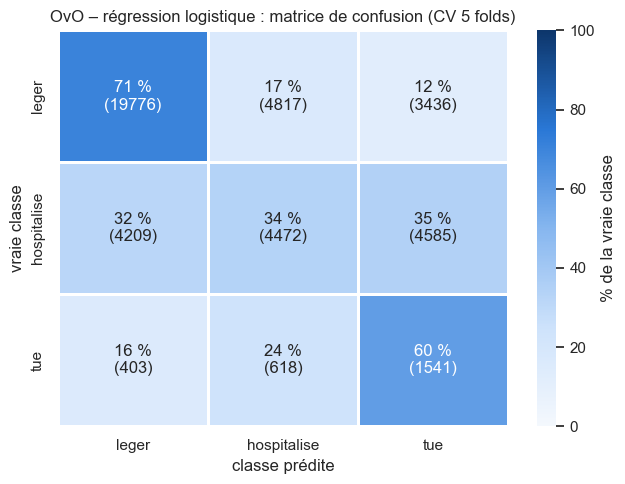

              precision    recall  f1-score   support

       leger      0.811     0.706     0.755     28029
 hospitalise      0.451     0.337     0.386     13266
         tue      0.161     0.601     0.254      2562

    accuracy                          0.588     43857
   macro avg      0.474     0.548     0.465     43857
weighted avg      0.664     0.588     0.614     43857



In [7]:
modele_ovo = make_pipeline(preprocesseur(), ovo)
y_pred = cross_val_predict(modele_ovo, X_train_fe, y_train, cv=CV, n_jobs=-1)

mc = confusion_matrix(y_train, y_pred, labels=CLASSES)
mc_pct = pd.DataFrame(mc / mc.sum(axis=1, keepdims=True) * 100, index=CLASSES, columns=CLASSES)
annot = mc_pct.round(0).astype(int).astype(str) + " %\n(" + pd.DataFrame(mc, index=CLASSES, columns=CLASSES).astype(str) + ")"

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(mc_pct, annot=annot, fmt="", cmap=BLEUS, vmin=0, vmax=100, linewidths=2, linecolor="white",
            cbar_kws={"label": "% de la vraie classe"}, ax=ax)
ax.set(xlabel="classe prédite", ylabel="vraie classe", title="OvO – régression logistique : matrice de confusion (CV 5 folds)")
plt.tight_layout(); plt.show()

print(classification_report(y_train, y_pred, labels=CLASSES, digits=3))

**Interprétation de l'OvO avec régression logistique.**
- **Scores** : F1 macro 0,465, balanced accuracy 0,548, **60 % des accidents mortels détectés**. Très au-dessus d'un classifieur naïf (prédire toujours `leger` donne un F1 macro de 0,26 et ne détecte aucun tué).
- **Pas de sur-apprentissage** : scores d'entraînement et de validation quasi identiques (écart < 0,01), et très stables d'un fold à l'autre (écart-type ≤ 0,02). Le modèle est plutôt **trop simple** (sous-apprentissage) : des frontières linéaires ne suffisent pas, ce qui justifie la suite (version polynomiale, ensembles d'arbres).
- **`hospitalise` est la classe la plus difficile** : seulement 34 % bien classés, le reste se répartit à parts presque égales entre `leger` (32 %) et `tue` (35 %). C'est la classe « du milieu », coincée entre les deux autres.
- **Le prix du rappel des tués** : avec `class_weight="balanced"`, le modèle prédit `tue` souvent (≈ 9 600 fois pour 2 562 vrais tués). Sa **précision sur `tue` n'est que de 16 %** : 3 436 accidents légers et 4 585 hospitalisés sont prédits mortels. Selon l'usage (alerter les secours ou non), ce compromis rappel / précision pourra être déplacé en changeant les poids des classes.

### Les 3 classifieurs binaires
Le modèle ajusté sur tout le train contient bien 3 régressions logistiques, une par paire. Pour voir ce qui sépare chaque paire de classes, on regarde l'**effet d'un écart-type** de chaque variable : coefficient × écart-type de la variable (après prétraitement). Le coefficient brut seul serait trompeur : une modalité rare (par exemple `int_8`, passage à niveau, quelques dizaines d'accidents) peut avoir un gros coefficient tout en ne jouant presque sur aucun accident.

Chaque paire est orientée dans le sens de la gravité : **positif (bleu) = pousse vers la classe la plus grave** de la paire, négatif (rouge) = vers la moins grave. Les codes des modalités (`catr_1`, `col_6`…) sont détaillés dans le README.

3 classifieurs binaires : hospitalise / leger, hospitalise / tue, leger / tue


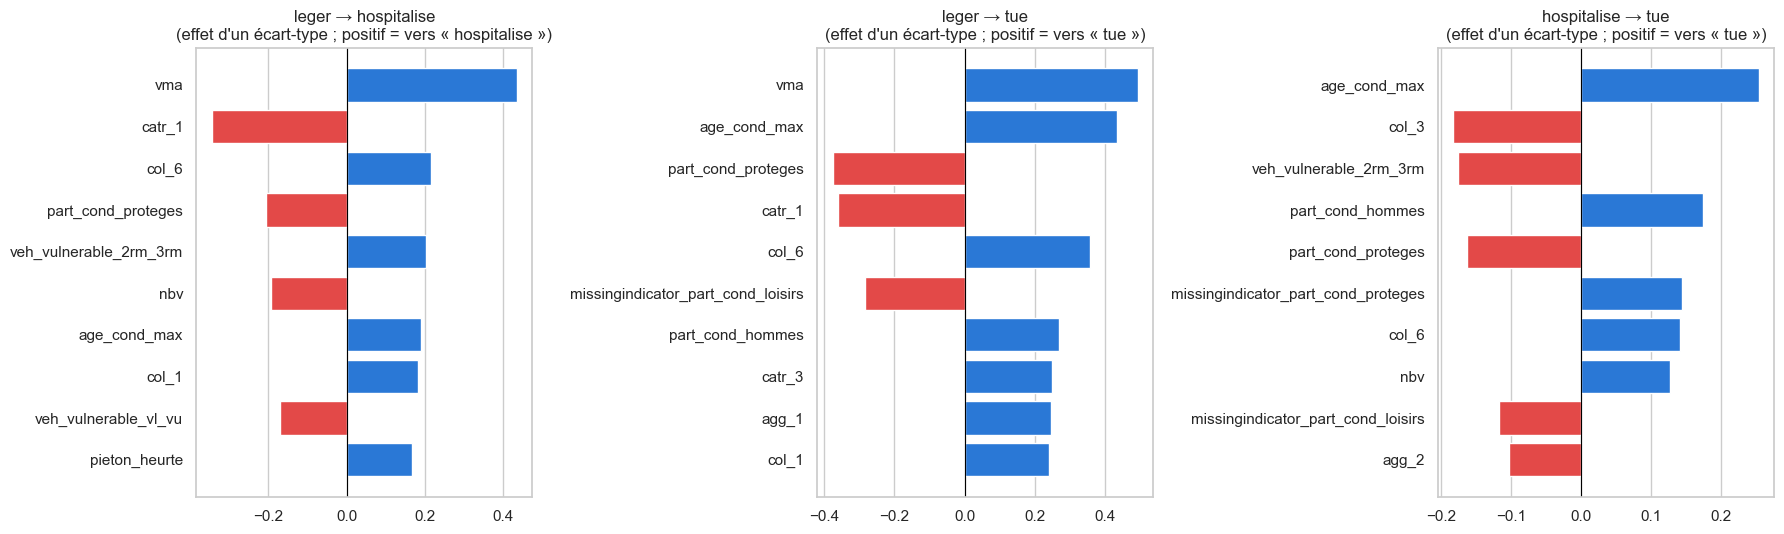

In [8]:
modele_ovo.fit(X_train_fe, y_train)
clf = modele_ovo[-1]
Xp = pd.DataFrame(modele_ovo[0].transform(X_train_fe),
                  columns=[n.split("__", 1)[1] for n in modele_ovo[0].get_feature_names_out()])
k = len(clf.classes_)
paires_classes = [(clf.classes_[i], clf.classes_[j]) for i in range(k) for j in range(i + 1, k)]  # ordre de scikit-learn
print(f"{len(clf.estimators_)} classifieurs binaires :", ", ".join(f"{a} / {b}" for a, b in paires_classes))

effets = {}
for (a, b), est in zip(paires_classes, clf.estimators_):
    effet = pd.Series(est.coef_[0], index=Xp.columns) * Xp.std()   # coefficient positif = vers la classe b
    moins, plus = sorted((a, b), key=CLASSES.index)                 # on réoriente : positif = vers la plus grave
    effets[f"{moins} → {plus}"] = effet if b == plus else -effet
effets = pd.DataFrame(effets)[["leger → hospitalise", "leger → tue", "hospitalise → tue"]]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for a, col in zip(axes, effets.columns):
    top = effets[col].reindex(effets[col].abs().sort_values().index[-10:])
    a.barh(top.index, top, color=["#2a78d6" if v > 0 else "#e34948" for v in top])
    a.axvline(0, color="black", lw=0.8); a.grid(axis="y", visible=False)
    a.set_title(f"{col}\n(effet d'un écart-type ; positif = vers « {col.split(' → ')[1]} »)")
plt.tight_layout(); plt.show()

**Interprétation des 3 classifieurs** (codes : `catr_1` autoroute, `catr_3` route départementale, `agg_1` hors agglomération, `agg_2` en agglomération, `col_1` collision frontale, `col_3` par le côté, `col_6` autre collision, surtout avec piéton) :
- **`leger` / `hospitalise`** : la vitesse autorisée (`vma`) pousse vers l'hospitalisation, mais **l'autoroute pousse vers « léger »** à vitesse égale (routes séparées, sans obstacle ni circulation en face) : on retrouve l'effet non monotone de `vma` vu dans l'exploration. Deux-roues motorisés, piétons (`col_6`) et conducteurs non protégés poussent vers l'hospitalisation.
- **`leger` / `tue`** : mêmes facteurs, plus marqués : vitesse, **âge du conducteur le plus âgé**, absence de protection, routes départementales hors agglomération, collisions frontales.
- **`hospitalise` / `tue`** : la séparation la plus difficile (effets tous ≤ 0,25). Le facteur principal est **l'âge** (fragilité des personnes âgées : à blessure égale, le risque de décès est plus élevé). Les collisions par le côté et les deux-roues motorisés poussent vers « hospitalisé » plutôt que « tué ».
- Les **indicateurs de manquants** comptent : un motif de trajet non renseigné pousse vers les classes moins graves, comme vu dans l'exploration (section 2 du notebook 1). L'imputation avec indicateur était donc utile.